# Step 3 - PatchCore (official code) on BTAD

Running the authors' code on BTAD, a real industrial dataset the paper didn't use. Same settings as my MVTec AD run. Results go to Drive.

Cell 2: get the authors' code

In [3]:
!git clone https://github.com/amazon-science/patchcore-inspection.git
%cd /content/patchcore-inspection
!git rev-parse HEAD
!pip install -q faiss-cpu pretrainedmodels click scikit-image

# heatmap saving bug in the released code (same as step 2): use mvtec.py's ImageNet values
p = "bin/run_patchcore.py"
s = open(p).read()
s = s.replace('dataloaders["testing"].dataset.transform_std', '[0.229, 0.224, 0.225]')
s = s.replace('dataloaders["testing"].dataset.transform_mean', '[0.485, 0.456, 0.406]')
open(p, "w").write(s)
!git diff

Cloning into 'patchcore-inspection'...
remote: Enumerating objects: 365, done.
remote: Counting objects: 100% (36/36), done.
remote: Compressing objects: 100% (28/28), done.
remote: Total 365 (delta 13), reused 8 (delta 8), pack-reused 329 (from 1)
Receiving objects: 100% (365/365), 2.02 MiB | 9.45 MiB/s, done.
Resolving deltas: 100% (56/56), done.
/content/patchcore-inspection
fcaa92f124fb1ad74a7acf56726decd4b27cbcad
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.8/58.8 kB 5.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 90.9 MB/s eta 0:00:00
diff --git a/bin/run_patchcore.py b/bin/run_patchcore.py
index 8666b2b..de56307 100644
--- a/bin/run_patchcore.py
+++ b/bin/run_patchcore.py
@@ -146,10 +146,10 @@ def run(
 
                 def image_transform(image):
                     in_std = np.array(
-                        dataloaders["testing"].dataset.transform_std
+                        [0.229, 0.224, 0.225]
  

Cell 3: Drive and environment record

In [4]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys, json, subprocess, datetime, torch, torchvision, faiss
OUT_DIR = "/content/drive/MyDrive/COMP8240_PatchCore/step3_btad"
os.makedirs(f"{OUT_DIR}/raw_results", exist_ok=True)

env = {
    "date": datetime.datetime.now().isoformat(timespec="minutes"),
    "python": sys.version.split()[0],
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "faiss": faiss.__version__,
    "gpu": torch.cuda.get_device_name(0),
    "repo_commit": subprocess.check_output(["git", "rev-parse", "HEAD"]).decode().strip(),
}
print(json.dumps(env, indent=2))
json.dump(env, open(f"{OUT_DIR}/environment.json", "w"), indent=2)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
{
  "date": "2026-10-06T07:33",
  "python": "3.13.15",
  "torch": "2.11.0+cu130",
  "torchvision": "0.26.0+cu130",
  "faiss": "1.15.1",
  "gpu": "Tesla T4",
  "repo_commit": "fcaa92f124fb1ad74a7acf56726decd4b27cbcad"
}


Cell 4: download BTAD and convert it to the MVTec folder layout

In [5]:
!pip install -q anomalib
from anomalib.data import BTech
import glob
import numpy as np
import pandas as pd
from PIL import Image

# only using anomalib to download BTAD
BTech(root="/content/datasets/BTAD", category="01").prepare_data()

SRC, DST = "/content/datasets/BTAD", "/content/datasets/BTAD_mvtec"

def link_all(src_dir, dst_dir):
    os.makedirs(dst_dir, exist_ok=True)
    files = sorted(glob.glob(f"{src_dir}/*"))
    for f in files:
        dst = f"{dst_dir}/{os.path.basename(f)}"
        if not os.path.exists(dst):
            os.symlink(f, dst)
    return files

rows = []
for cat in ["01", "02", "03"]:
    root = os.path.dirname(glob.glob(f"{SRC}/**/{cat}/train", recursive=True)[0])
    train = link_all(f"{root}/train/ok", f"{DST}/{cat}/train/good")
    good = link_all(f"{root}/test/ok", f"{DST}/{cat}/test/good")
    bad = link_all(f"{root}/test/ko", f"{DST}/{cat}/test/ko")

    # masks: same name as their image (code pairs them by sorted order), and saved as
    # 1-channel 0/255 because product 03's originals are RGB and the code expects 1 channel
    masks = {os.path.splitext(os.path.basename(m))[0]: m for m in glob.glob(f"{root}/ground_truth/ko/*")}
    os.makedirs(f"{DST}/{cat}/ground_truth/ko", exist_ok=True)
    orig_mode = Image.open(next(iter(masks.values()))).mode
    missing = 0
    for img in bad:
        stem = os.path.splitext(os.path.basename(img))[0]
        if stem in masks:
            m = np.array(Image.open(masks[stem]).convert("L"))
            Image.fromarray(((m > 0) * 255).astype("uint8")).save(f"{DST}/{cat}/ground_truth/ko/{stem}.png")
        else:
            missing += 1

    rows.append({"product": cat, "train_good": len(train), "test_good": len(good), "test_defective": len(bad),
                 "masks_missing": missing, "original_mask_mode": orig_mode,
                 "image_size": Image.open(train[0]).size, "file_type": os.path.splitext(train[0])[1]})

info = pd.DataFrame(rows).set_index("product")
display(info)
info.to_csv(f"{OUT_DIR}/btad_dataset_info.csv")

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 66.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 246.1/246.1 kB 28.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 60.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 63.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 71.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.1/28.1 MB 76.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 140.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 800.2/800.2 kB 56.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 67.1 MB/s eta 0:00:00


btech: 1.23GB [01:11, 17.2MB/s]                            
Converting: 1952it [01:33, 20.97it/s]


,train_good,test_good,test_defective,masks_missing,original_mask_mode,image_size,file_type
product,,,,,,,
01,400,21,49,0,L,"(1600, 1600)",.png
02,399,30,200,0,L,"(600, 600)",.png
03,1000,400,41,0,RGB,"(800, 600)",.png


Cell 5a: products 01 and 02

In [7]:
%%bash
OUT=/content/drive/MyDrive/COMP8240_PatchCore/step3_btad/raw_results
cd /content/patchcore-inspection
time PYTHONPATH=src python bin/run_patchcore.py --gpu 0 --seed 0 --save_segmentation_images \
  --log_group WR50_btad_0102 --log_project official results \
  patch_core -b wideresnet50 -le layer2 -le layer3 \
  --pretrain_embed_dimension 1024 --target_embed_dimension 1024 \
  --anomaly_scorer_num_nn 1 --patchsize 3 \
  sampler -p 0.1 approx_greedy_coreset \
  dataset --resize 256 --imagesize 224 -d 01 -d 02 mvtec /content/datasets/BTAD_mvtec
# save straight to Drive in case the runtime disconnects
cp -r results/official/WR50_btad_0102* "$OUT/"
ls "$OUT"

Downloading: "https://download.pytorch.org/models/wide_resnet50_2-95faca4d.pth" to /root/.cache/torch/hub/checkpoints/wide_resnet50_2-95faca4d.pth
WR50_btad_0102
WR50_btad_0102_0


INFO:__main__:Command line arguments: bin/run_patchcore.py --gpu 0 --seed 0 --save_segmentation_images --log_group WR50_btad_0102 --log_project official results patch_core -b wideresnet50 -le layer2 -le layer3 --pretrain_embed_dimension 1024 --target_embed_dimension 1024 --anomaly_scorer_num_nn 1 --patchsize 3 sampler -p 0.1 approx_greedy_coreset dataset --resize 256 --imagesize 224 -d 01 -d 02 mvtec /content/datasets/BTAD_mvtec
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
INFO:__main__:Evaluating dataset [mvtec_01] (1/2)...
/usr/local/lib/python3.13/dist-pack

Cell 5b: product 03 alone

In [8]:
%%bash
OUT=/content/drive/MyDrive/COMP8240_PatchCore/step3_btad/raw_results
free -h
cd /content/patchcore-inspection
time PYTHONPATH=src python bin/run_patchcore.py --gpu 0 --seed 0 --save_segmentation_images \
  --log_group WR50_btad_03 --log_project official results \
  patch_core -b wideresnet50 -le layer2 -le layer3 \
  --pretrain_embed_dimension 1024 --target_embed_dimension 1024 \
  --anomaly_scorer_num_nn 1 --patchsize 3 \
  sampler -p 0.1 approx_greedy_coreset \
  dataset --resize 256 --imagesize 224 -d 03 mvtec /content/datasets/BTAD_mvtec
cp -r results/official/WR50_btad_03* "$OUT/"
ls "$OUT"

               total        used        free      shared  buff/cache   available
Mem:            12Gi       2.1Gi       4.4Gi       4.1Mi       6.4Gi        10Gi
Swap:             0B          0B          0B
WR50_btad_0102
WR50_btad_0102_0
WR50_btad_03


INFO:__main__:Command line arguments: bin/run_patchcore.py --gpu 0 --seed 0 --save_segmentation_images --log_group WR50_btad_03 --log_project official results patch_core -b wideresnet50 -le layer2 -le layer3 --pretrain_embed_dimension 1024 --target_embed_dimension 1024 --anomaly_scorer_num_nn 1 --patchsize 3 sampler -p 0.1 approx_greedy_coreset dataset --resize 256 --imagesize 224 -d 03 mvtec /content/datasets/BTAD_mvtec
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
INFO:__main__:Evaluating dataset [mvtec_03] (1/1)...
/usr/local/lib/python3.13/dist-packages/tor

Cell 6: results table and chart

['/content/drive/MyDrive/COMP8240_PatchCore/step3_btad/raw_results/WR50_btad_0102_0/results.csv', '/content/drive/MyDrive/COMP8240_PatchCore/step3_btad/raw_results/WR50_btad_03/results.csv']


,instance_auroc,full_pixel_auroc,anomaly_pixel_auroc
Row Names,,,
01,96.7,97.0,95.6
02,81.4,95.8,95.0
03,100.0,99.2,92.8
Mean,92.7,97.4,94.5


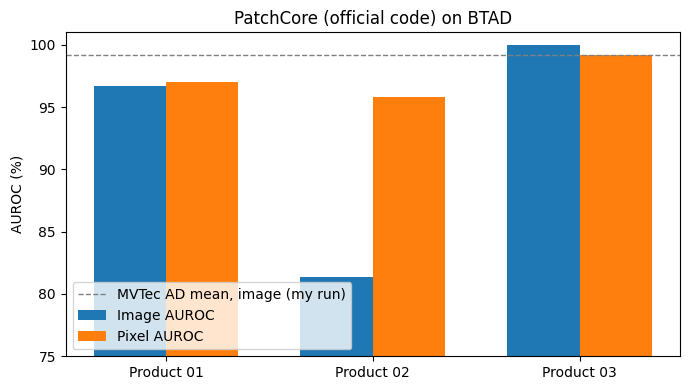

In [9]:
import matplotlib.pyplot as plt

fs = sorted(glob.glob(f"{OUT_DIR}/raw_results/WR50_btad_*/results.csv"))
print(fs)
raw = pd.concat([pd.read_csv(f) for f in fs])
res = raw[raw[raw.columns[0]] != "Mean"].set_index(raw.columns[0])
res.index = res.index.str.replace("mvtec_", "", regex=False)
res = res[~res.index.duplicated(keep="last")].sort_index()
res.loc["Mean"] = res.mean()
res = (res * 100).round(1)
display(res)
res.to_csv(f"{OUT_DIR}/btad_results.csv")
res.to_latex(f"{OUT_DIR}/btad_results.tex", float_format="%.1f")

prod = res.drop(index="Mean")
x = np.arange(len(prod)); w = 0.35
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(x - w/2, prod["instance_auroc"], w, label="Image AUROC")
ax.bar(x + w/2, prod["full_pixel_auroc"], w, label="Pixel AUROC")
ax.axhline(99.2, color="grey", linestyle="--", linewidth=1, label="MVTec AD mean, image (my run)")
ax.set_xticks(x); ax.set_xticklabels([f"Product {c}" for c in prod.index])
# y axis doesn't start at 0, so the gaps are visible
ax.set_ylim(75, 101); ax.set_ylabel("AUROC (%)"); ax.legend(loc="lower left")
ax.set_title("PatchCore (official code) on BTAD")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/btad_auroc.png", dpi=200); plt.show()

Cell 7: heatmaps

290 segmentation images found


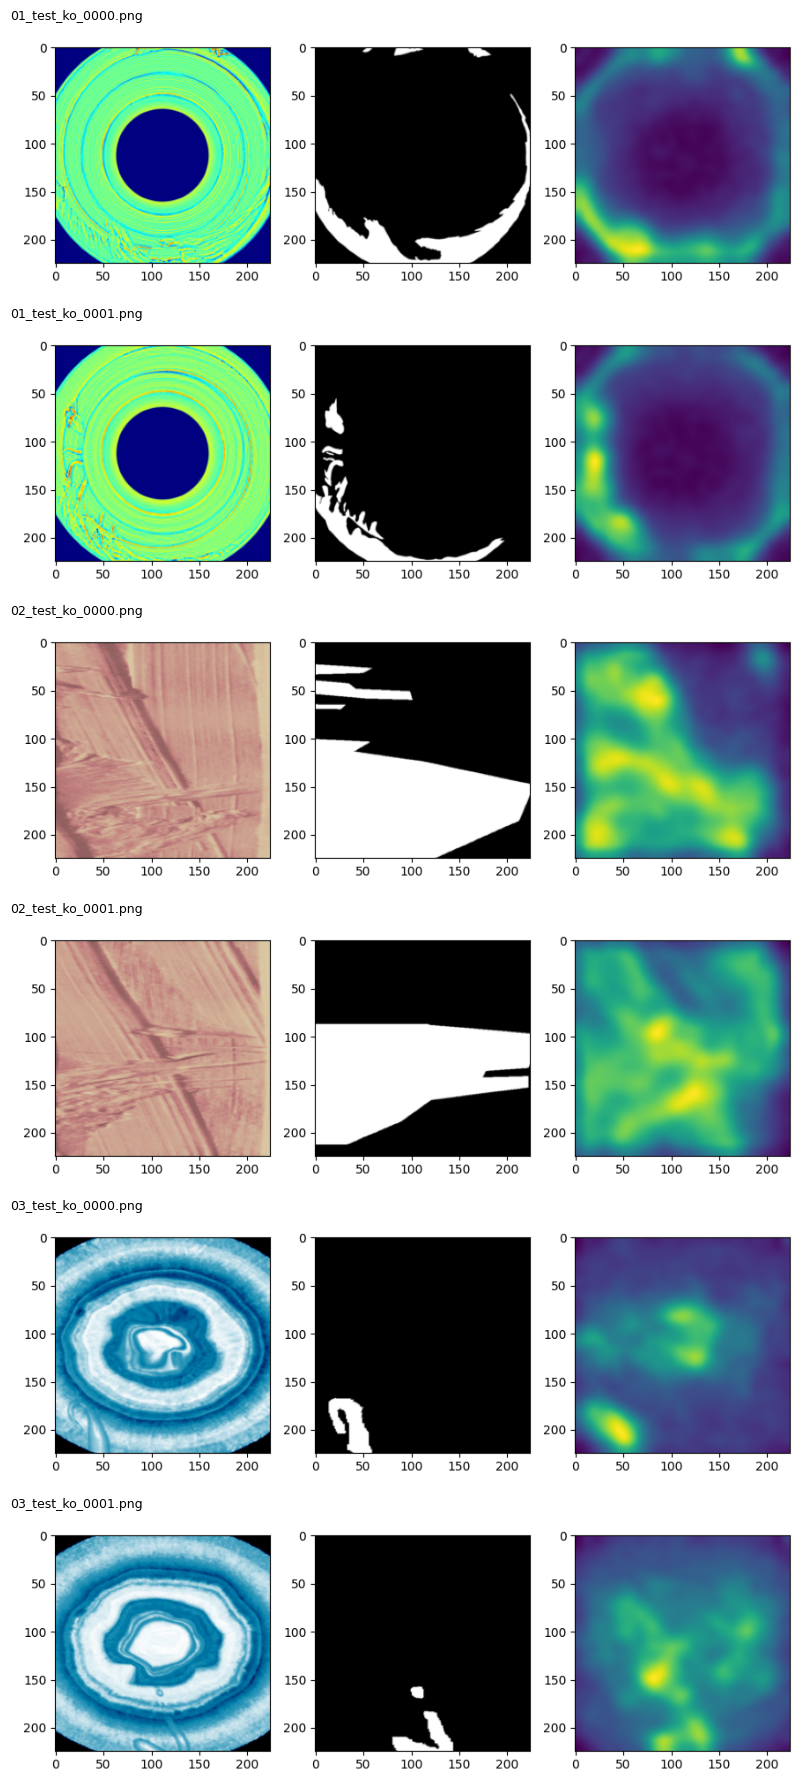

In [10]:
import shutil
from PIL import Image as PILImage

seg = [p for p in glob.glob(f"{OUT_DIR}/raw_results/WR50_btad_*/**/*.*", recursive=True)
       if p.lower().endswith((".png", ".jpg")) and "good" not in p]
print(len(seg), "segmentation images found")

HEAT_DIR = f"{OUT_DIR}/heatmaps"; os.makedirs(HEAT_DIR, exist_ok=True)
picked = []
for cat in ["01", "02", "03"]:
    picked += [p for p in sorted(seg) if f"/{cat}/" in p or os.path.basename(p).startswith(f"{cat}_")][:2]
for p in picked:
    shutil.copy(p, HEAT_DIR)

fig, axes = plt.subplots(len(picked), 1, figsize=(10, 3 * len(picked)))
for ax, p in zip(np.atleast_1d(axes), picked):
    ax.imshow(PILImage.open(p)); ax.set_title(os.path.basename(p), loc="left", fontsize=9); ax.axis("off")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/btad_heatmaps.png", dpi=150); plt.show()

BTAD overview figure

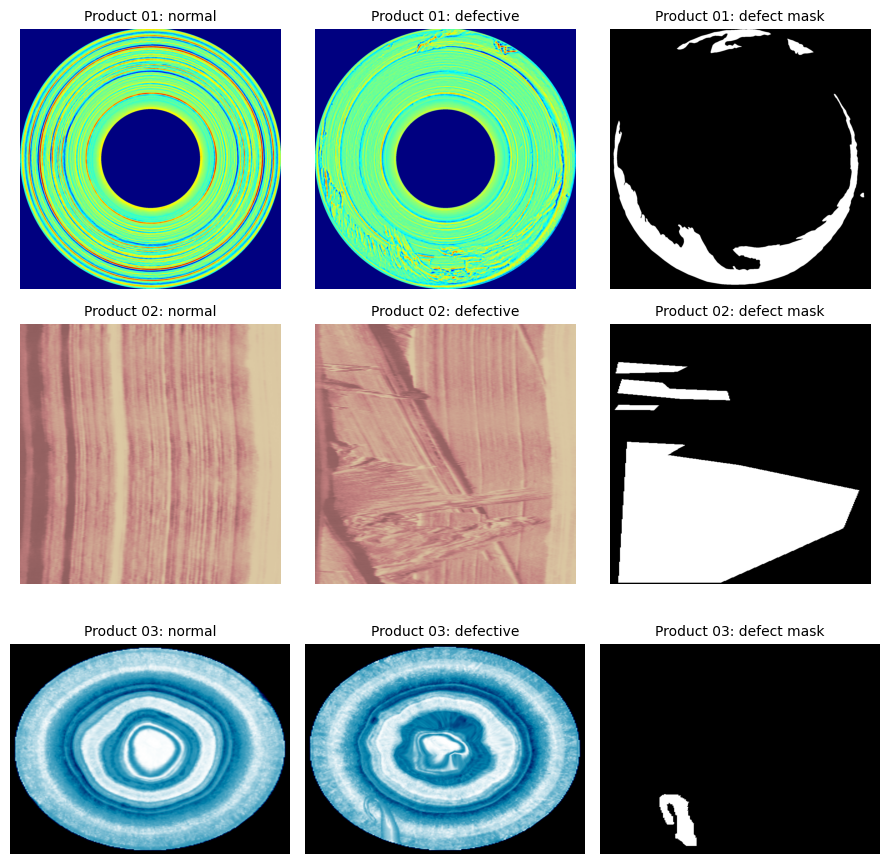

In [11]:
fig, axes = plt.subplots(3, 3, figsize=(9, 9))
for r, cat in enumerate(["01", "02", "03"]):
    good = sorted(glob.glob(f"{DST}/{cat}/test/good/*"))[0]
    bad = sorted(glob.glob(f"{DST}/{cat}/test/ko/*"))[0]
    mask = sorted(glob.glob(f"{DST}/{cat}/ground_truth/ko/*"))[0]
    for c, (p, title) in enumerate([(good, "normal"), (bad, "defective"), (mask, "defect mask")]):
        axes[r, c].imshow(Image.open(p).convert("RGB"))
        axes[r, c].set_title(f"Product {cat}: {title}", fontsize=10)
        axes[r, c].axis("off")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/btad_overview.png", dpi=150); plt.show()